# Time Series Preprocessing Analysis

We first check the training-based Z-normalization used in the existing FCN code on Adiac. We then explore the data and examine how preprocessing changes the sequences.

## Adiac Baseline: Training-Based Z-Normalization

We calculate the mean and standard deviation from the Adiac training split. We then use the same values to normalize both the training and test splits.

In [1]:
import numpy as np

def readucr(filename):
    data = np.loadtxt(filename, delimiter=",")
    Y = data[:, 0]
    X = data[:, 1:]
    return X, Y


# Load the original Adiac splits
adiac_X_train, adiac_y_train = readucr("Adiac/Adiac_TRAIN")
adiac_X_test, adiac_y_test = readucr("Adiac/Adiac_TEST")

# Calculate normalization statistics from training data only
adiac_train_mean = adiac_X_train.mean()
adiac_train_std = adiac_X_train.std()

# Apply the same statistics to both splits
adiac_X_train_z = (
    adiac_X_train - adiac_train_mean
) / adiac_train_std

adiac_X_test_z = (
    adiac_X_test - adiac_train_mean
) / adiac_train_std

# Check shapes and normalization results
print("Training shape:", adiac_X_train.shape)
print("Test shape:", adiac_X_test.shape)
print("Training classes:", len(np.unique(adiac_y_train)))
print("Original training mean:", adiac_train_mean)
print("Original training std:", adiac_train_std)
print("Normalized training mean:", adiac_X_train_z.mean())
print("Normalized training std:", adiac_X_train_z.std())
print("Normalized test mean:", adiac_X_test_z.mean())
print("Normalized test std:", adiac_X_test_z.std())

Training shape: (390, 176)
Test shape: (391, 176)
Training classes: 37
Original training mean: -7.232727272908289e-08
Original training std: 0.9971551735624088
Normalized training mean: 4.829081967250681e-17
Normalized training std: 1.0
Normalized test mean: -4.349429283901982e-08
Normalized test std: 0.9999997099374602


### Normalization Check

The Adiac training split contains 390 sequences, and the test split contains 391. Each sequence has 176 time points, and there are 37 classes in the training split.

Before normalization, the training mean is already close to zero and the standard deviation is about 0.9972. After applying training-based Z-normalization, the training mean is approximately zero and the standard deviation is one. The test split uses the same training statistics.

## Adiac Data Overview

We check the training and test splits, class labels, and missing values before exploring the sequences. Each row contains one sample, and each column represents a time point. The files do not include timestamps, so we use the time index when plotting.

In [2]:
import pandas as pd

# Select one training sample for inspection
adiac_sample_index = 0

# Check the structure and basic quality of both splits
adiac_summary = pd.DataFrame({
    "Split": ["Training", "Test"],
    "Samples": [
        adiac_X_train.shape[0],
        adiac_X_test.shape[0]
    ],
    "Time points": [
        adiac_X_train.shape[1],
        adiac_X_test.shape[1]
    ],
    "Classes": [
        len(np.unique(adiac_y_train)),
        len(np.unique(adiac_y_test))
    ],
    "Missing values": [
        np.isnan(adiac_X_train).sum(),
        np.isnan(adiac_X_test).sum()
    ],
    "Infinite values": [
        np.isinf(adiac_X_train).sum(),
        np.isinf(adiac_X_test).sum()
    ]
})

display(adiac_summary)

# Check whether both splits contain the same class labels
adiac_train_classes = np.unique(adiac_y_train)
adiac_test_classes = np.unique(adiac_y_test)

print("Training class labels:", adiac_train_classes)
print("Test class labels:", adiac_test_classes)
print(
    "Same class labels in both splits:",
    np.array_equal(adiac_train_classes, adiac_test_classes)
)

# Inspect the first ten values of the selected sample
print("\nSample index:", adiac_sample_index)
print("Sample class:", int(adiac_y_train[adiac_sample_index]))

adiac_sample_preview = pd.DataFrame({
    "Time index": np.arange(10),
    "Original value": adiac_X_train[adiac_sample_index, :10],
    "Normalized value": adiac_X_train_z[adiac_sample_index, :10]
})

display(adiac_sample_preview)

,Split,Samples,Time points,Classes,Missing values,Infinite values
0,Training,390,176,37,0,0
1,Test,391,176,37,0,0


Training class labels: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35. 36.
 37.]
Test class labels: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35. 36.
 37.]
Same class labels in both splits: True

Sample index: 0
Sample class: 22


,Time index,Original value,Normalized value
0,0,1.5980,1.602559
1,1,1.5994,1.603963
2,2,1.5705,1.574981
3,3,1.5505,1.554924
4,4,1.5074,1.511701
5,5,1.4343,1.438392
6,6,1.3690,1.372906
7,7,1.3053,1.309024
8,8,1.2103,1.213753
9,9,1.1167,1.119886


### Data Checks

Both splits contain sequences of length 176 and the same 37 class labels, numbered from 1 to 37. No missing or infinite values were found in the sequence values, so no imputation is needed.

Training sample 0 belongs to Class 22. Its first ten values change only slightly after training-based Z-normalization, which agrees with the earlier normalization check. Here, original values refer to the values loaded from the Adiac files.

### Before and After Z-Normalization

We plot the same Adiac training sample before and after training-based Z-normalization to see how its values change.

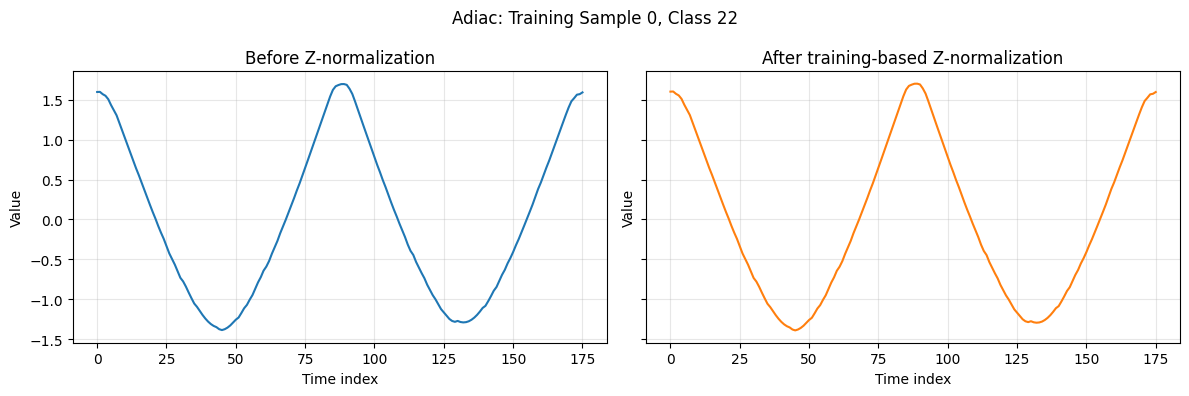

In [3]:
import matplotlib.pyplot as plt

# Select one training sample
adiac_sample_index = 0
adiac_sample_label = int(adiac_y_train[adiac_sample_index])

# Compare the same sequence before and after normalization
fig, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharex=True, sharey=True
)

axes[0].plot(adiac_X_train[adiac_sample_index], color="C0")
axes[0].set_title("Before Z-normalization")

axes[1].plot(adiac_X_train_z[adiac_sample_index], color="C1")
axes[1].set_title("After training-based Z-normalization")

for ax in axes:
    ax.set_xlabel("Time index")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.3)

fig.suptitle(
    f"Adiac: Training Sample {adiac_sample_index}, "
    f"Class {adiac_sample_label}"
)
plt.tight_layout()
plt.show()

### Observation

The two plots look almost identical. This agrees with the earlier statistics, where the training mean was already close to zero and the standard deviation was close to one. Training-based Z-normalization makes only a small change to the values and preserves the shape of the sequence.

## Adiac Training Sequence Visualization

We plot three training samples from each class after training-based Z-normalization. This lets us compare the shapes across classes and the variation within each class. We use the same axis scales to make the plots easier to compare.

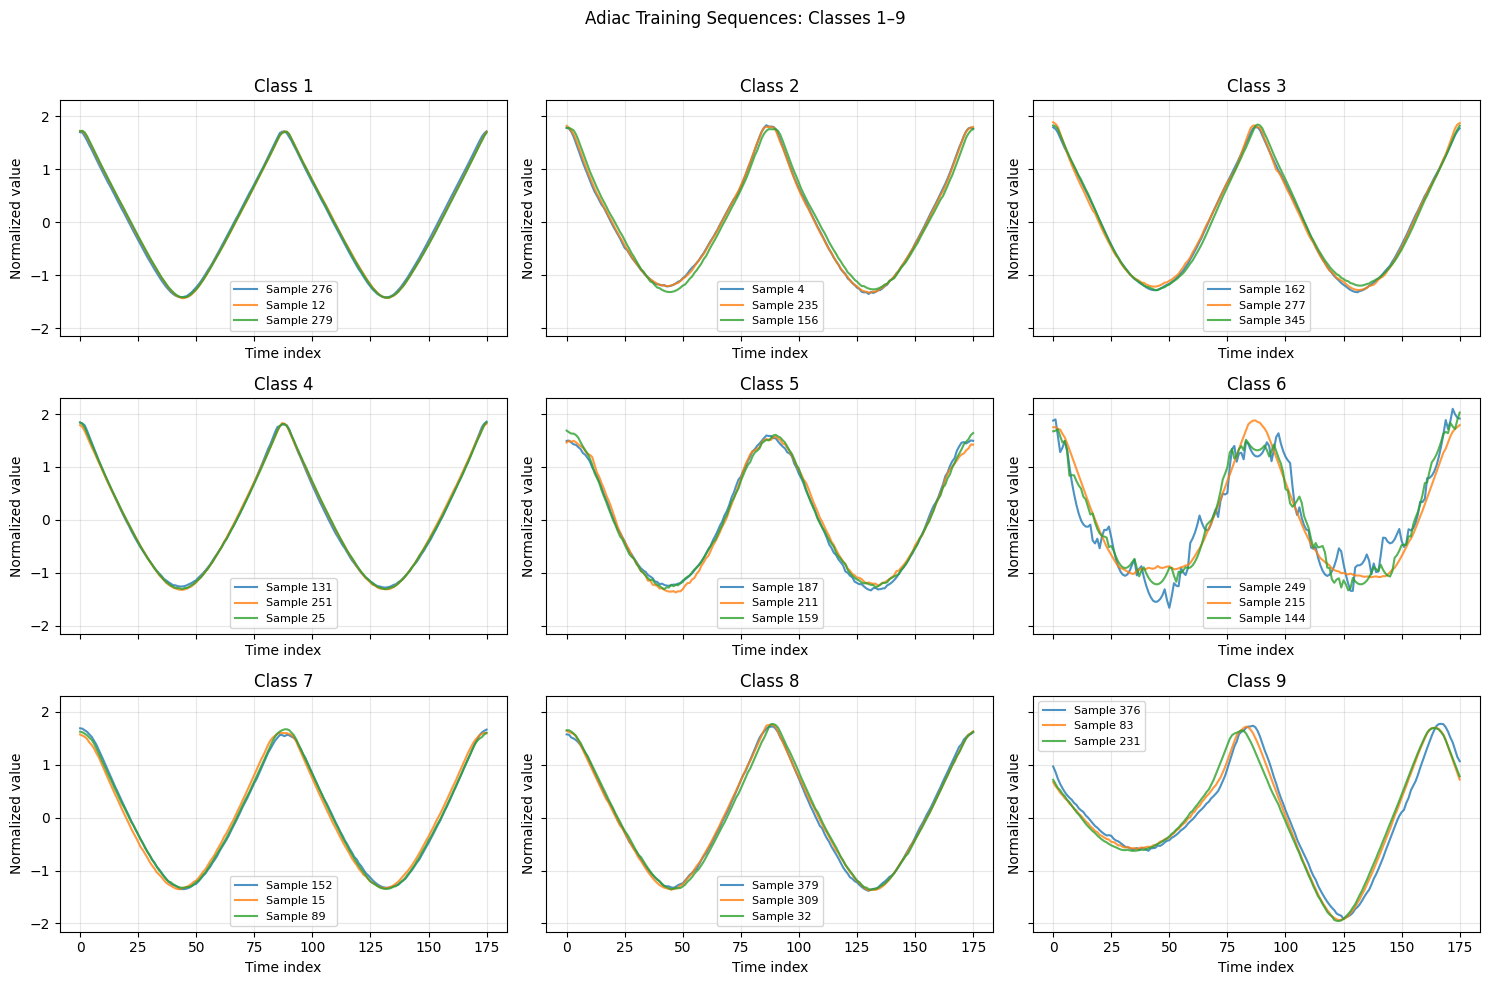

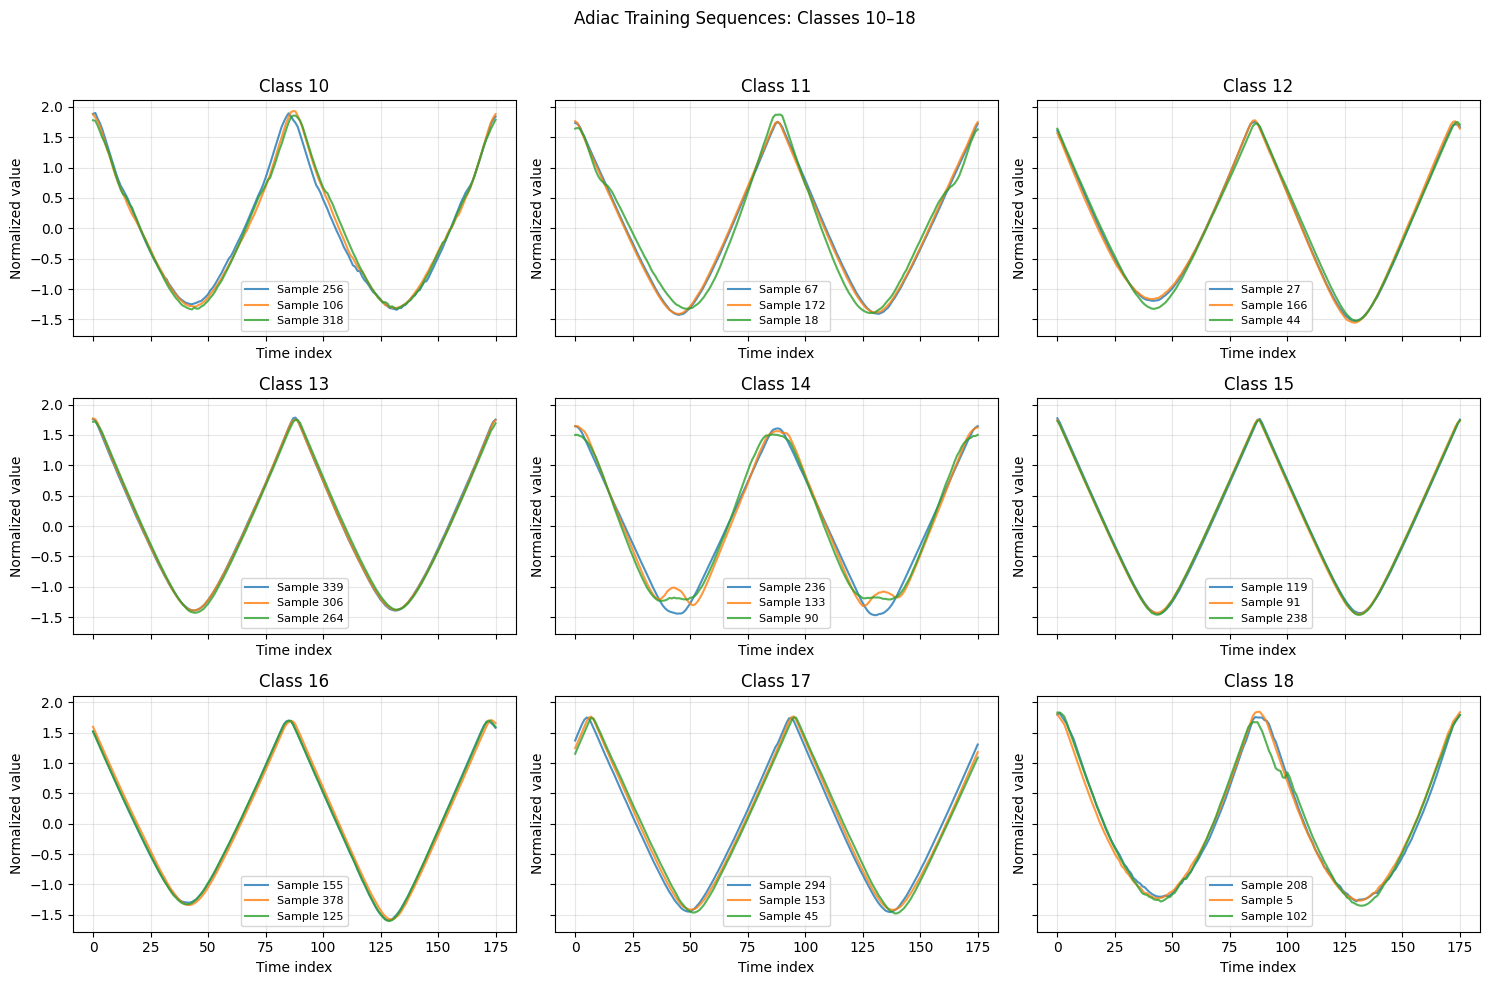

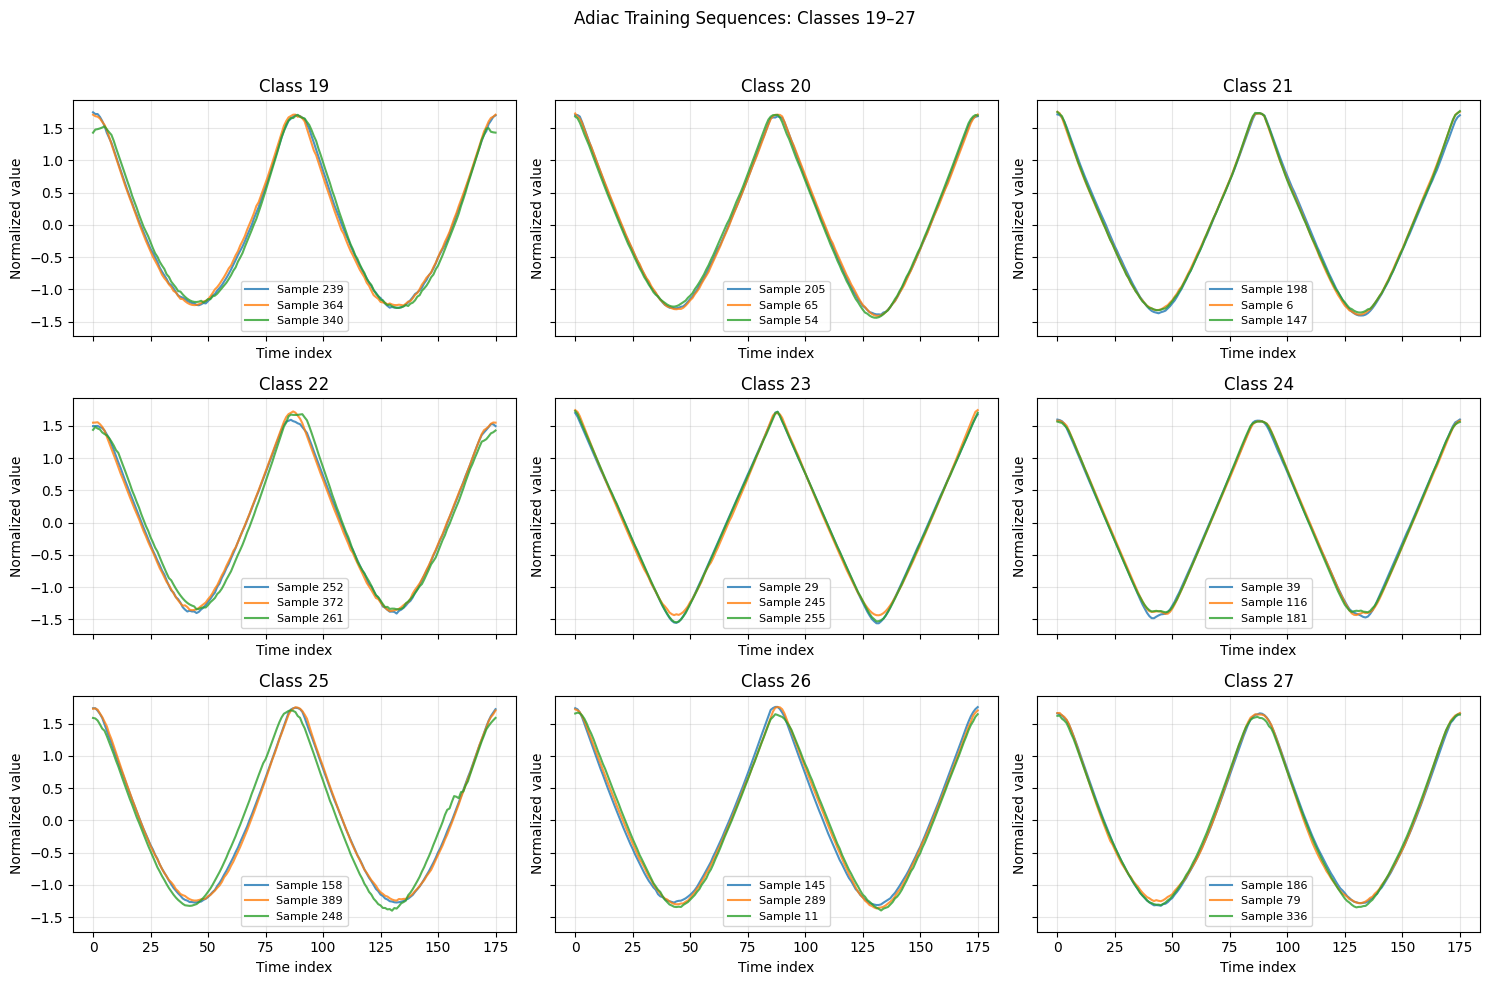

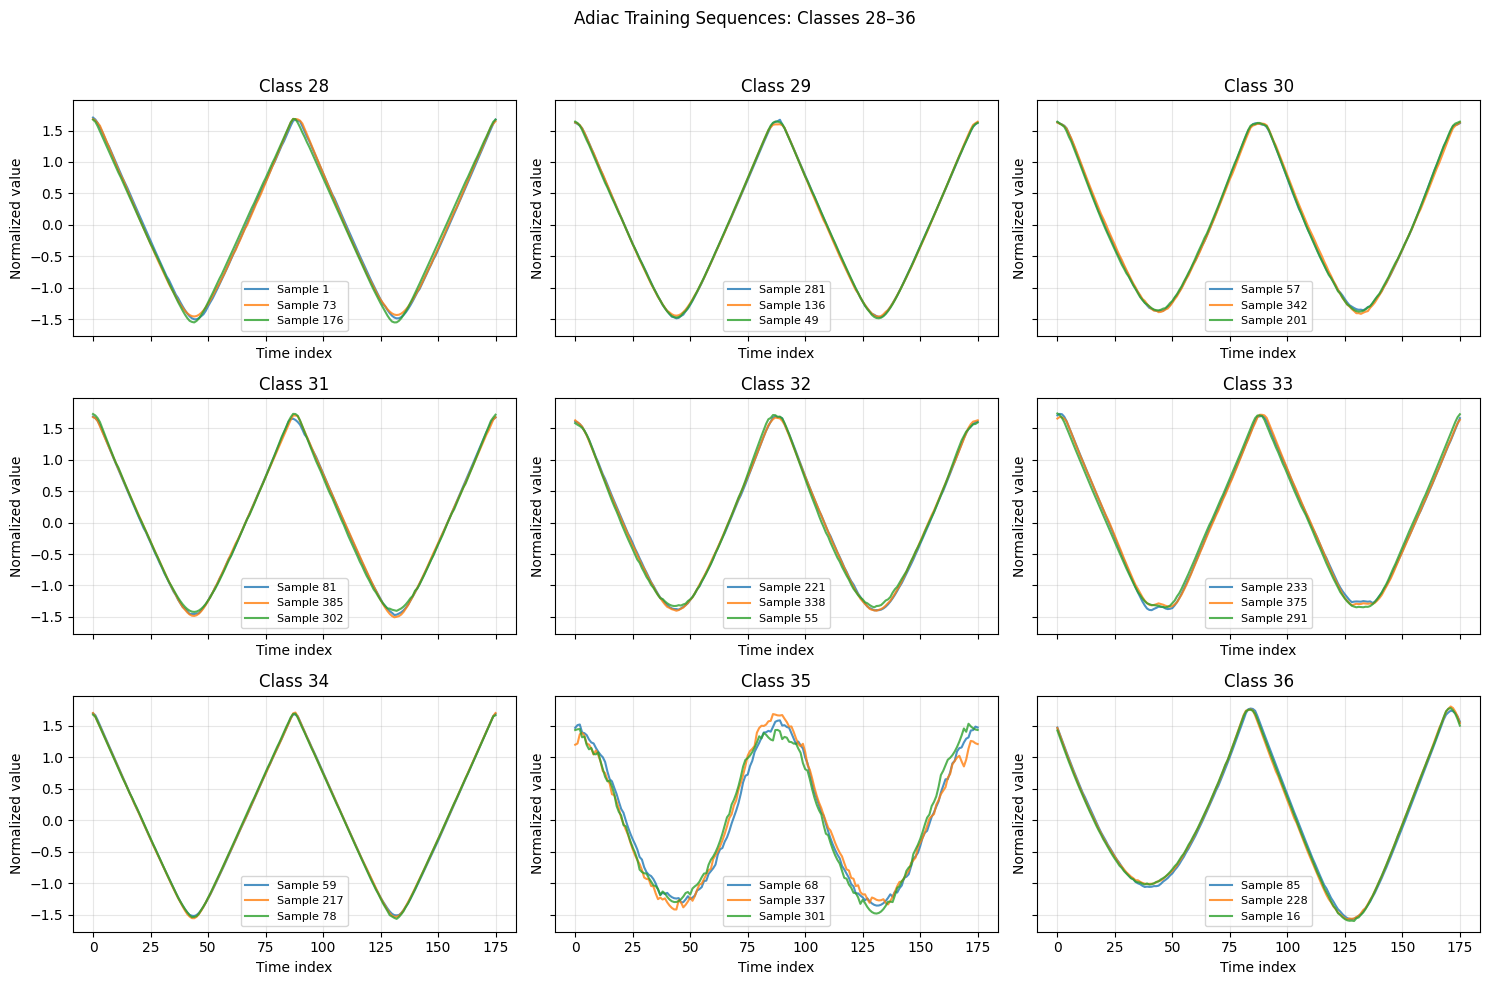

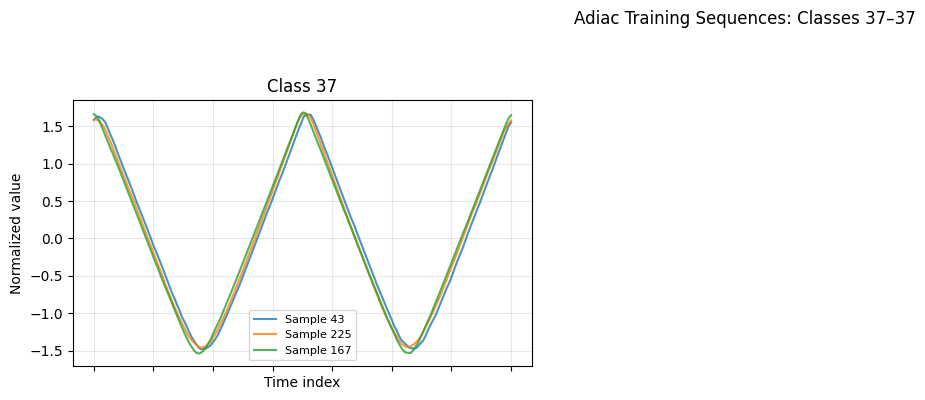

In [4]:
import matplotlib.pyplot as plt

# Select reproducible samples from every training class
adiac_rng = np.random.default_rng(42)
adiac_plot_classes = np.unique(adiac_y_train)
adiac_selected_samples = {}

# Show classes in groups to keep each figure readable
adiac_classes_per_figure = 9

for start in range(0, len(adiac_plot_classes), adiac_classes_per_figure):
    figure_classes = adiac_plot_classes[
        start:start + adiac_classes_per_figure
    ]

    fig, axes = plt.subplots(
        3, 3, figsize=(15, 10), sharex=True, sharey=True
    )

    for ax, class_label in zip(axes.flat, figure_classes):
        class_indices = np.where(adiac_y_train == class_label)[0]

        selected_indices = adiac_rng.choice(
            class_indices,
            size=min(3, len(class_indices)),
            replace=False
        )

        # Keep the selected indices for later comparisons
        adiac_selected_samples[int(class_label)] = selected_indices

        for sample_index in selected_indices:
            ax.plot(
                adiac_X_train_z[sample_index],
                label=f"Sample {sample_index}",
                alpha=0.8
            )

        ax.set_title(f"Class {int(class_label)}")
        ax.set_xlabel("Time index")
        ax.set_ylabel("Normalized value")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

    # Hide unused panels in the final figure
    for ax in axes.flat[len(figure_classes):]:
        ax.set_visible(False)

    fig.suptitle(
        "Adiac Training Sequences: "
        f"Classes {int(figure_classes[0])}–{int(figure_classes[-1])}"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

### Sequence Observations

Many of the plotted sequences have similar overall shapes, including two broad troughs and a central peak. Within several classes, the selected samples overlap closely. Other classes, such as Classes 6, 14, 25 and 35, show more noticeable variation in local shape or peak position.

Some differences between classes are subtle. These details may be useful for classification, so we should check how preprocessing changes them rather than assume that all local fluctuations are noise.

These observations describe the selected training samples. The plots alone do not establish stationarity or confirm seasonality.

## Adiac Value Distributions

We use a histogram and a boxplot to examine the values of the same training sample used earlier. We also plot a histogram of all normalized training values for an overall view.

These plots summarise the value distributions, but they do not show the order of the time points or establish stationarity.

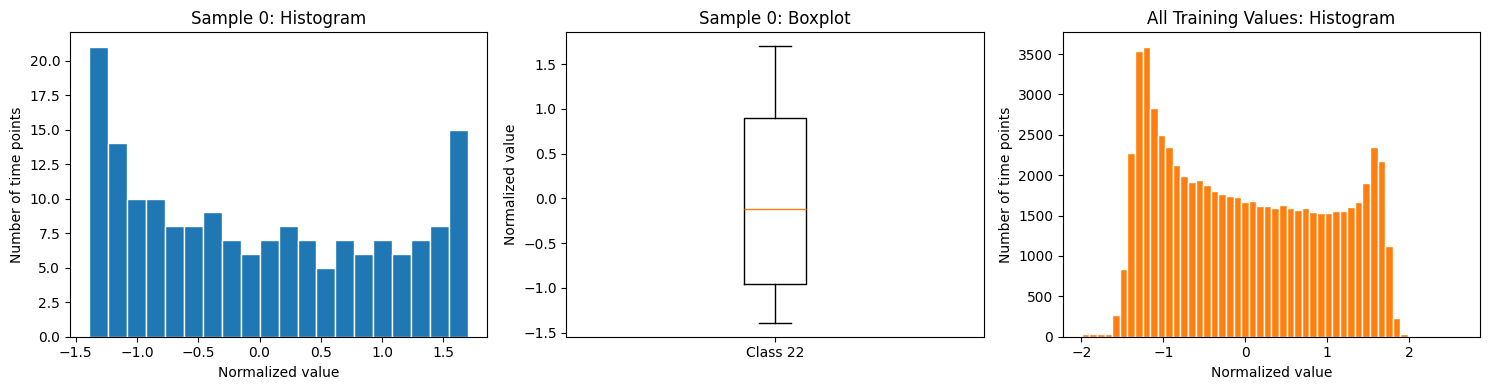

In [5]:
# Use the same normalized training sample as before
adiac_sample_label = int(adiac_y_train[adiac_sample_index])
adiac_sample_values = adiac_X_train_z[adiac_sample_index]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Show the distribution of values within one sample
axes[0].hist(
    adiac_sample_values,
    bins=20,
    color="C0",
    edgecolor="white"
)
axes[0].set_title(f"Sample {adiac_sample_index}: Histogram")
axes[0].set_xlabel("Normalized value")
axes[0].set_ylabel("Number of time points")

# Summarise the same sample using a boxplot
axes[1].boxplot(adiac_sample_values)
axes[1].set_title(f"Sample {adiac_sample_index}: Boxplot")
axes[1].set_xticks([1])
axes[1].set_xticklabels([f"Class {adiac_sample_label}"])
axes[1].set_ylabel("Normalized value")

# Pool values for a descriptive overview of the training split
axes[2].hist(
    adiac_X_train_z.ravel(),
    bins=50,
    color="C1",
    edgecolor="white"
)
axes[2].set_title("All Training Values: Histogram")
axes[2].set_xlabel("Normalized value")
axes[2].set_ylabel("Number of time points")

plt.tight_layout()
plt.show()

### Distribution Observations

For Sample 0, the histogram has more values near the lower and upper ends than in the middle. The boxplot shows a median slightly below zero and no points beyond the whiskers.

The histogram of all training values also has higher counts near the lower and upper parts of the distribution. Training-based Z-normalization sets the overall training mean to approximately zero and the standard deviation to one, but it does not make the distribution normal.

These plots describe the values without preserving their time order, so they cannot establish stationarity.

## Additive Decomposition: Suitability for Adiac

Additive decomposition represents a sequence as:

Observed = Trend + Seasonal + Residual

The seasonal component requires a specified period. The Adiac files do not provide timestamps or a documented seasonal period. Although the plotted samples have similar peaks and troughs, this alone does not confirm seasonality.

We therefore do not apply seasonal decomposition at this stage. Choosing a period without sufficient evidence could produce misleading components. We continue with ACF/PACF and formal stationarity tests to examine the sequences further.

## Adiac Analysis: ACF and PACF

We examine the ACF and PACF of the same training sample after training-based Z-normalization. This helps us look at the relationship between values at different lags. We will use these plots alongside stationarity tests rather than decide from the plots alone.

In [6]:
%pip install aeon seaborn statsmodels

Note: you may need to restart the kernel to use updated packages.


Adiac training sample 0, Class 22


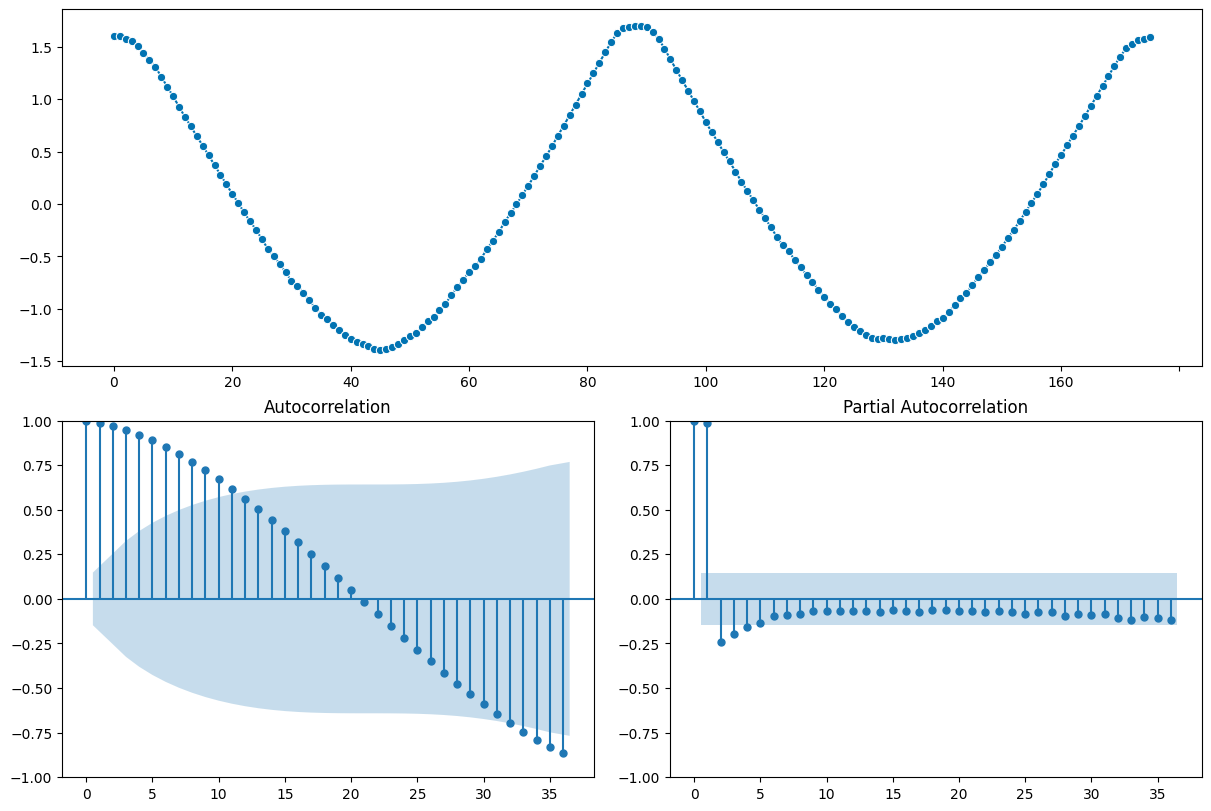

In [7]:
import pandas as pd
from aeon.visualisation import plot_correlations

# Use the same Adiac sample shown in the previous plots
adiac_ts = pd.Series(adiac_X_train_z[adiac_sample_index])

# Plot the normalized sequence, ACF and PACF
print(
    f"Adiac training sample {adiac_sample_index}, "
    f"Class {adiac_sample_label}"
)
plot_correlations(adiac_ts, lags=36, alpha=0.05)
plt.show()

### ACF and PACF Observations

The ACF is strongly positive at short lags and gradually becomes negative as the lag increases. This matches the smooth, oscillating shape of the sequence. The PACF has a large value at lag 1, while the values at later lags are much smaller.

These plots show strong dependence between nearby time points, but they do not establish whether the sequence is stationary. We next use the ADF and KPSS tests to investigate this.

## Formal Stationarity Tests

We apply the ADF and KPSS tests to normalized training Sample 0 using a significance level of 0.05.

The ADF test has a unit-root null hypothesis, while the KPSS test has a level-stationarity null hypothesis. We use a constant term in both tests and interpret the results together with the sequence and correlation plots.

This first check describes one sample, rather than the whole Adiac dataset.

In [8]:
from statsmodels.tsa.stattools import adfuller, kpss

# Use the same normalized training sample as in the previous plots
adiac_sample_label = int(adiac_y_train[adiac_sample_index])
adiac_ts = pd.Series(adiac_X_train_z[adiac_sample_index])

adiac_significance_level = 0.05

# Test the unit-root null hypothesis
adiac_adf_result = adfuller(
    adiac_ts,
    regression="c",
    autolag="AIC"
)

# Test the level-stationarity null hypothesis
adiac_kpss_result = kpss(
    adiac_ts,
    regression="c",
    nlags="auto"
)

# Summarise both test results
adiac_test_results = pd.DataFrame({
    "Test": ["ADF", "KPSS"],
    "Statistic": [
        adiac_adf_result[0],
        adiac_kpss_result[0]
    ],
    "p-value": [
        adiac_adf_result[1],
        adiac_kpss_result[1]
    ],
    "Lags used": [
        adiac_adf_result[2],
        adiac_kpss_result[2]
    ],
    "Reject H0 at 0.05": [
        adiac_adf_result[1] < adiac_significance_level,
        adiac_kpss_result[1] < adiac_significance_level
    ]
})

print(
    f"Adiac training sample {adiac_sample_index}, "
    f"Class {adiac_sample_label}"
)
display(adiac_test_results)

# Interpret the tests jointly without treating them as proof
adiac_adf_reject = (
    adiac_adf_result[1] < adiac_significance_level
)
adiac_kpss_reject = (
    adiac_kpss_result[1] < adiac_significance_level
)

if adiac_adf_reject and not adiac_kpss_reject:
    print(
        "The results are consistent with level stationarity "
        "under these test settings."
    )
elif not adiac_adf_reject and adiac_kpss_reject:
    print(
        "The results suggest non-stationarity "
        "under these test settings."
    )
elif adiac_adf_reject and adiac_kpss_reject:
    print(
        "Both null hypotheses are rejected. "
        "The results need further investigation."
    )
else:
    print(
        "Neither null hypothesis is rejected. "
        "The results are inconclusive."
    )

Adiac training sample 0, Class 22


C:\Users\user\AppData\Local\Temp\ipykernel_11496\3268985807.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adiac_adf_result = adfuller(
C:\Users\user\AppData\Local\Temp\ipykernel_11496\3268985807.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  adiac_kpss_result = kpss(
C:\Users\user\AppData\Local\Temp\ipykernel_11496\3268985807.py:17: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the 

,Test,Statistic,p-value,Lags used,Reject H0 at 0.05
0,ADF,-7.115445,3.841621e-10,3,True
1,KPSS,0.121249,1.000000e-01,9,False


The results are consistent with level stationarity under these test settings.


### Stationarity Test Results for Sample 0

The ADF test gives a p-value of approximately 3.84 × 10⁻¹⁰, so we reject the unit-root null hypothesis at the 0.05 significance level. The KPSS test does not reject level stationarity. Its reported p-value of 0.10 is an upper table boundary; the warning indicates that the actual p-value is greater than 0.10.

Together, these results are consistent with level stationarity under the chosen test settings. They do not prove stationarity or represent all Adiac samples. For this sample, the tests do not provide a clear reason to apply differencing solely to address non-stationarity.

We next apply the same tests to each training sequence separately.

## Stationarity Checks Across Training Samples

We apply the same ADF and KPSS settings to each training sequence separately. We summarise the results overall and by class to see whether the result for Sample 0 is common.

These are exploratory checks at the 0.05 significance level, without a multiple-testing correction. The categories describe the test outcomes rather than prove stationarity.

In [9]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

adiac_stationarity_rows = []

# Test each training sequence separately
for sample_index, sequence in enumerate(adiac_X_train_z):
    # Record warnings without printing hundreds of repeated messages
    with warnings.catch_warnings(record=True) as recorded_warnings:
        warnings.simplefilter("always")

        adf_result = adfuller(
            sequence,
            regression="c",
            autolag="AIC"
        )

        kpss_result = kpss(
            sequence,
            regression="c",
            nlags="auto"
        )

    adf_reject = adf_result[1] < 0.05
    kpss_reject = kpss_result[1] < 0.05

    if adf_reject and not kpss_reject:
        outcome = "Consistent with level stationarity"
    elif not adf_reject and kpss_reject:
        outcome = "Suggests non-stationarity"
    elif adf_reject and kpss_reject:
        outcome = "Both null hypotheses rejected"
    else:
        outcome = "Neither null hypothesis rejected"

    adiac_stationarity_rows.append({
        "Sample": sample_index,
        "Class": int(adiac_y_train[sample_index]),
        "ADF p-value": adf_result[1],
        "KPSS reported p-value": kpss_result[1],
        "Outcome": outcome,
        "Warnings": " | ".join(sorted({
            str(w.message) for w in recorded_warnings
        }))
    })

adiac_stationarity_results = pd.DataFrame(adiac_stationarity_rows)

# Summarise outcomes across all training samples
adiac_outcome_summary = (
    adiac_stationarity_results["Outcome"]
    .value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Samples")
)

adiac_outcome_summary["Percentage"] = (
    100 * adiac_outcome_summary["Samples"]
    / len(adiac_stationarity_results)
).round(2)

display(adiac_outcome_summary)

# Show the number of samples in each outcome category by class
adiac_class_summary = pd.crosstab(
    adiac_stationarity_results["Class"],
    adiac_stationarity_results["Outcome"]
)

display(adiac_class_summary)

print(
    "Samples with recorded warnings:",
    (adiac_stationarity_results["Warnings"] != "").sum()
)
print(
    "KPSS p-values at 0.01 or 0.10 are table boundaries; "
    "check the recorded warnings for their interpretation."
)

,Outcome,Samples,Percentage
0,Consistent with level stationarity,386,98.97
1,Neither null hypothesis rejected,4,1.03


Outcome,Consistent with level stationarity,Neither null hypothesis rejected
Class,,
1,13,0
2,10,0
3,5,0
4,14,0
5,4,0
6,8,4
7,10,0
8,13,0
9,9,0


Samples with recorded warnings: 390
KPSS p-values at 0.01 or 0.10 are table boundaries; check the recorded warnings for their interpretation.


### Training Sample Test Summary

Using the same settings, 386 of the 390 training sequences (98.97%) have test results consistent with level stationarity. For the remaining four sequences (1.03%), neither null hypothesis is rejected, so the results are inconclusive. All four belong to Class 6.

These exploratory results do not establish stationarity, but they do not provide a clear reason to difference every Adiac sequence. We next inspect the four inconclusive samples before deciding on preprocessing.

In [10]:
# Inspect samples with inconclusive test outcomes
adiac_inconclusive = adiac_stationarity_results[
    adiac_stationarity_results["Outcome"]
    == "Neither null hypothesis rejected"
].copy()

display(adiac_inconclusive[
    ["Sample", "Class", "ADF p-value", "KPSS reported p-value"]
])

,Sample,Class,ADF p-value,KPSS reported p-value
215,215,6,0.096547,0.1
220,220,6,0.122375,0.1
249,249,6,0.183663,0.1
387,387,6,0.441297,0.1


### Inspecting the Inconclusive Samples

Samples 215, 220, 249 and 387 all belong to Class 6. Their ADF tests do not reject the unit-root null hypothesis, while their KPSS tests do not reject level stationarity. We inspect their shapes to help understand these inconclusive results.

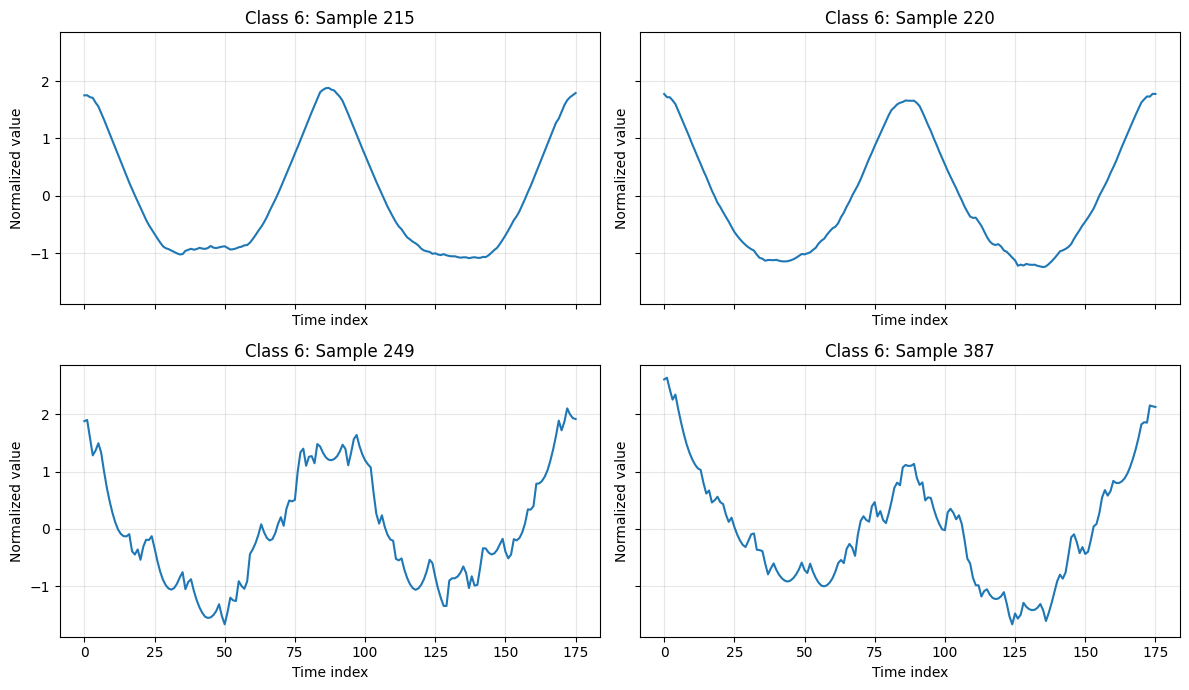

In [11]:
# Plot the four samples with inconclusive test results
fig, axes = plt.subplots(
    2, 2, figsize=(12, 7), sharex=True, sharey=True
)

for ax, sample_index in zip(
    axes.flat, adiac_inconclusive["Sample"]
):
    ax.plot(adiac_X_train_z[sample_index])

    ax.set_title(f"Class 6: Sample {sample_index}")
    ax.set_xlabel("Time index")
    ax.set_ylabel("Normalized value")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observations on the Inconclusive Samples

Samples 215 and 220 are relatively smooth, with broad troughs and a central peak. Samples 249 and 387 have more irregular local fluctuations, while retaining a similar overall shape. None of these plots shows a clear sustained upward or downward trend across the full sequence.

The visual differences do not resolve the inconclusive test results. We therefore keep these samples and do not automatically difference them or treat their local fluctuations as noise.

## First-Order Differencing Exploration

First-order differencing calculates the change between consecutive values:

Δx[t] = x[t] − x[t−1]

We apply it to the four samples with inconclusive test results and compare their shapes before and after differencing. This is an exploratory comparison, rather than a decision to replace the baseline input. Differencing changes the representation and reduces each sequence from 176 to 175 values.

Baseline training shape: (390, 176)
Differenced training shape: (390, 175)


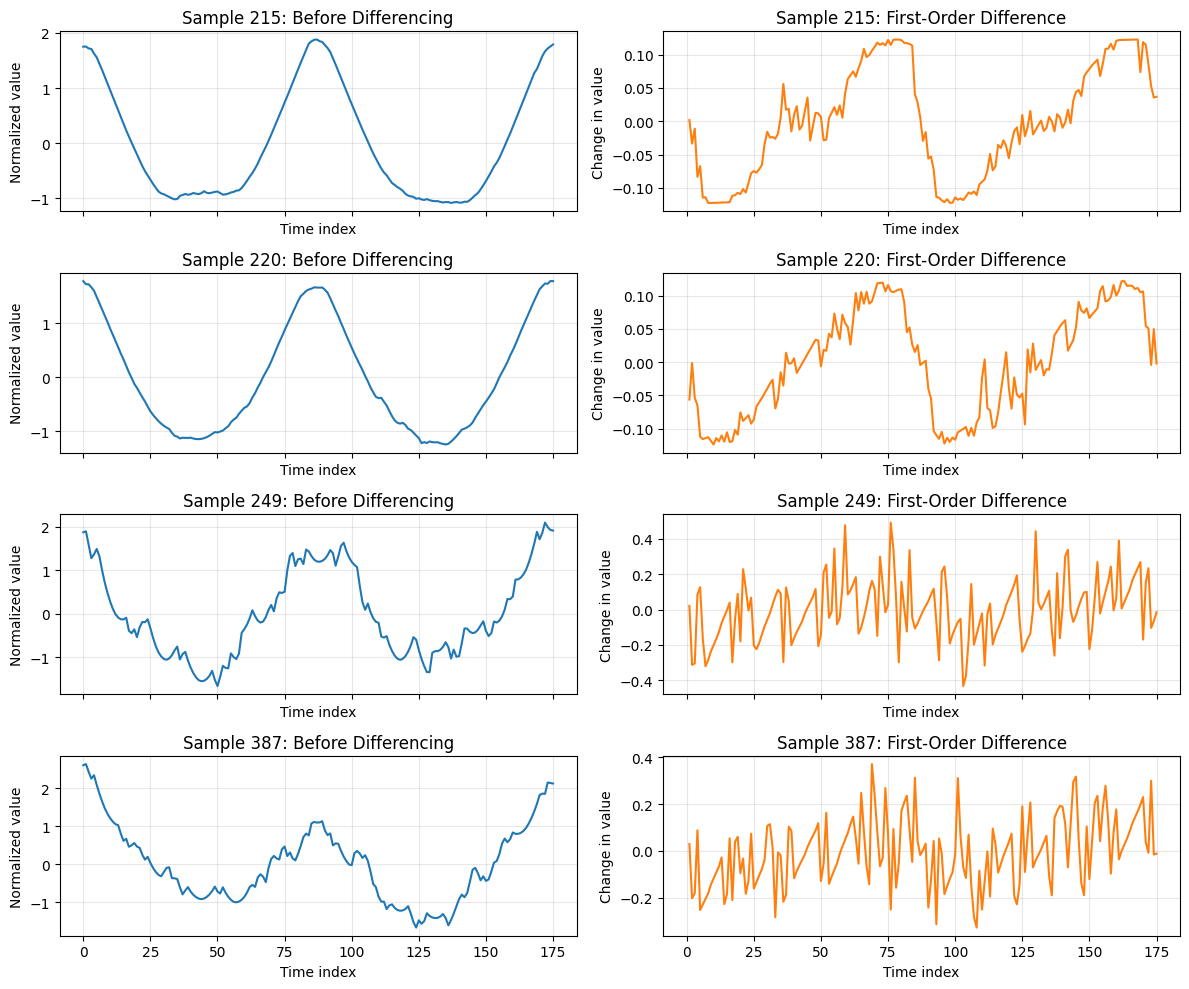

In [12]:
# Calculate first-order differences along each training sequence
adiac_X_train_diff = np.diff(adiac_X_train_z, axis=1)

print("Baseline training shape:", adiac_X_train_z.shape)
print("Differenced training shape:", adiac_X_train_diff.shape)

# Compare the same four samples before and after differencing
fig, axes = plt.subplots(
    len(adiac_inconclusive), 2,
    figsize=(12, 10),
    sharex=True,
    squeeze=False
)

for row, sample_index in enumerate(adiac_inconclusive["Sample"]):
    axes[row, 0].plot(adiac_X_train_z[sample_index])
    axes[row, 0].set_title(
        f"Sample {sample_index}: Before Differencing"
    )
    axes[row, 0].set_ylabel("Normalized value")

    # Align each difference with its later time point
    axes[row, 1].plot(
        np.arange(1, adiac_X_train_z.shape[1]),
        adiac_X_train_diff[sample_index],
        color="C1"
    )
    axes[row, 1].set_title(
        f"Sample {sample_index}: First-Order Difference"
    )
    axes[row, 1].set_ylabel("Change in value")

    for ax in axes[row]:
        ax.set_xlabel("Time index")
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### First-Order Differencing Observations

First-order differencing reduces each sequence from 176 to 175 values. For Samples 215 and 220, the differences retain broad positive and negative sections, corresponding to rises and falls in the baseline sequences.

Samples 249 and 387 show more prominent rapid fluctuations after differencing. The transformation emphasises changes between neighbouring values rather than their original levels.

These plots do not establish whether differencing improves stationarity or classification. We next examine the ACF/PACF and repeat the stationarity tests.

### ACF and PACF After Differencing

We examine the first-order differences of the same four samples to see how their dependence across lags changes.

First-order difference: Class 6, Sample 215


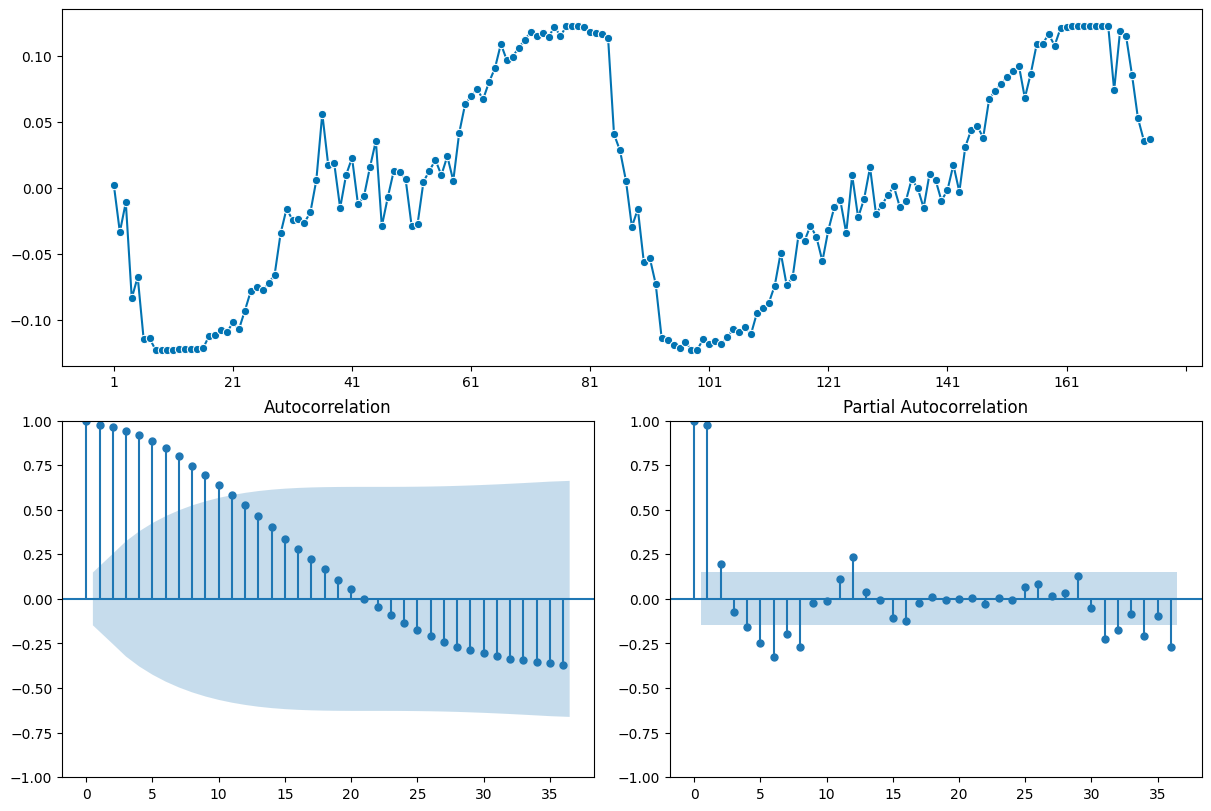

First-order difference: Class 6, Sample 220


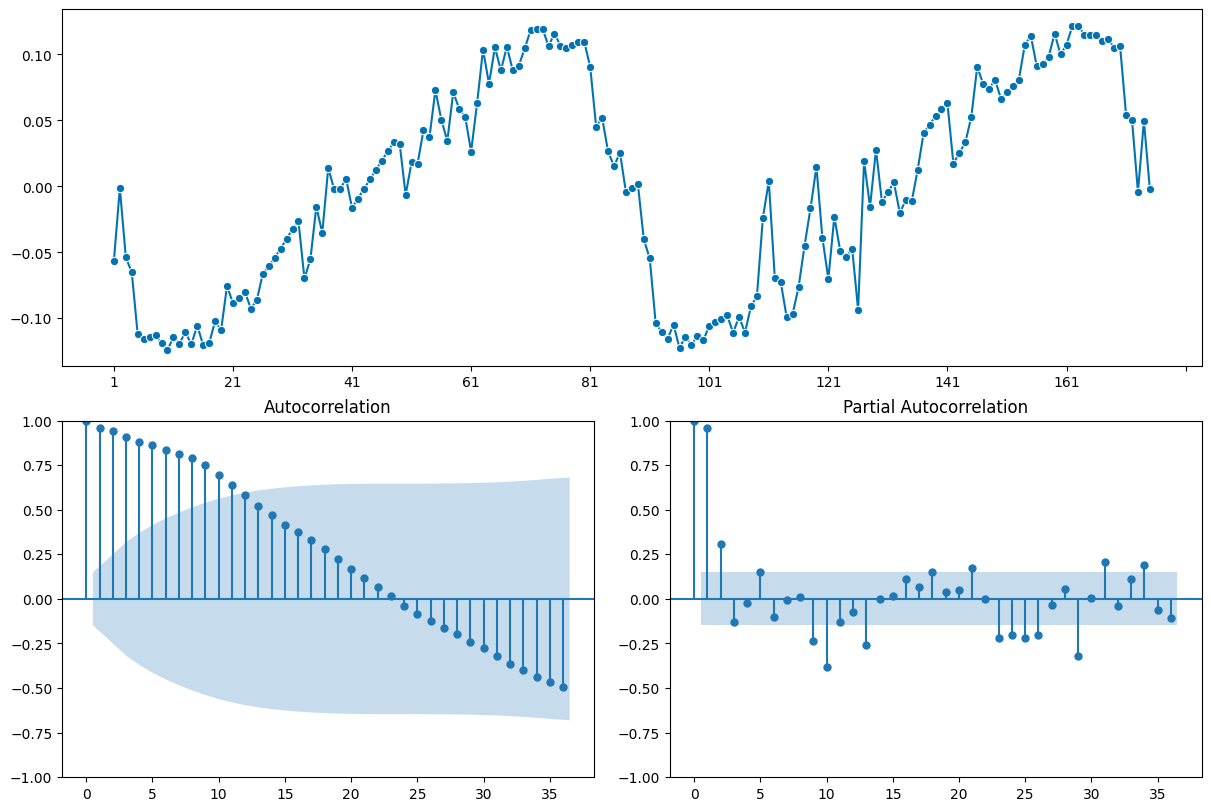

First-order difference: Class 6, Sample 249


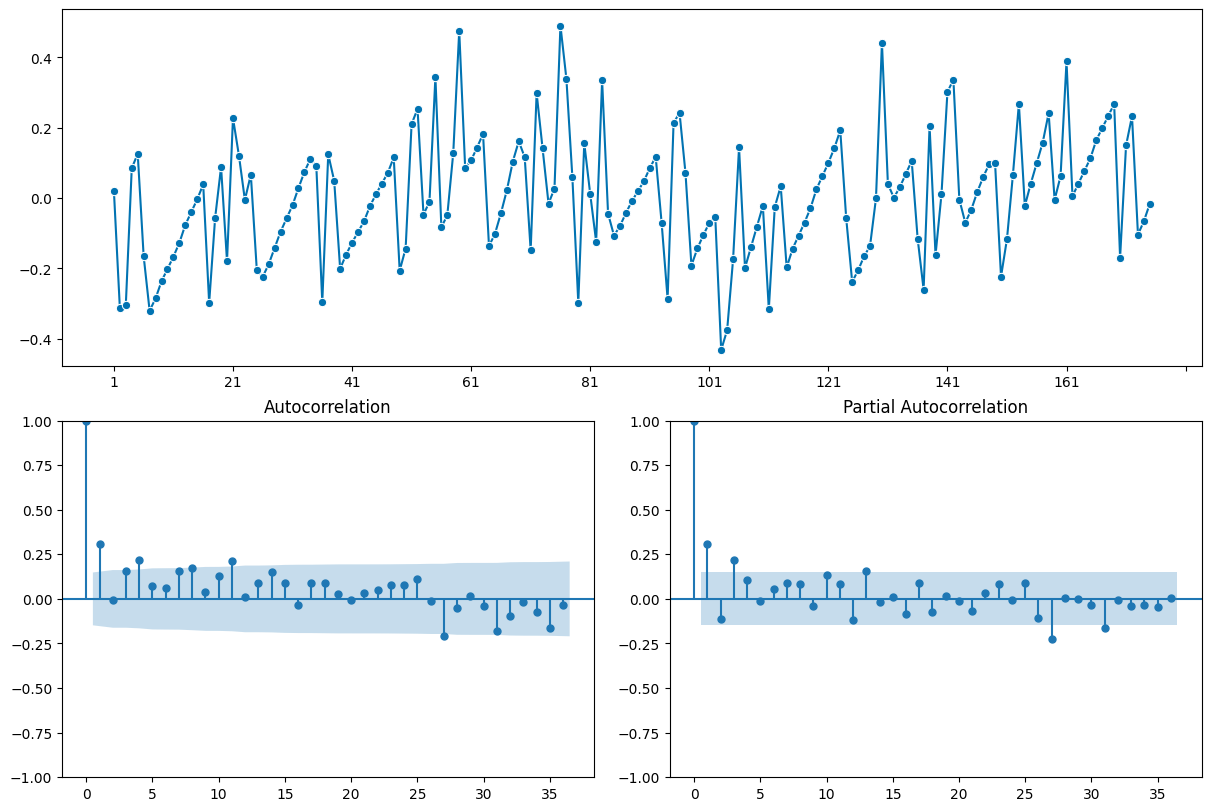

First-order difference: Class 6, Sample 387


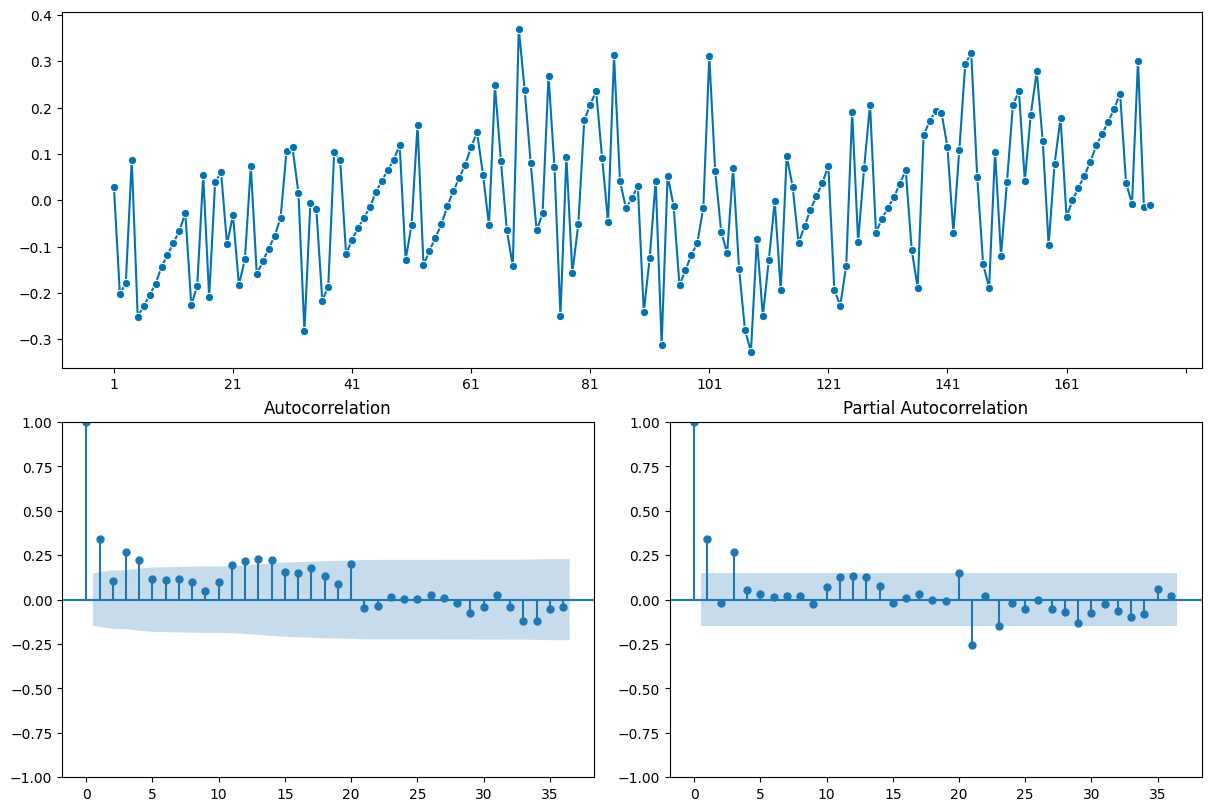

In [13]:
from aeon.visualisation import plot_correlations

# Examine the same four samples after first-order differencing
for sample_index in adiac_inconclusive["Sample"]:
    adiac_diff_ts = pd.Series(
        adiac_X_train_diff[sample_index],
        index=np.arange(1, adiac_X_train_z.shape[1])
    )

    print(f"First-order difference: Class 6, Sample {sample_index}")
    plot_correlations(adiac_diff_ts, lags=36, alpha=0.05)
    plt.show()

### ACF and PACF Observations After Differencing

Samples 215 and 220 still show strong autocorrelation at short lags, with the ACF decreasing gradually. Differencing has retained substantial dependence between neighbouring values.

Samples 249 and 387 have smaller ACF values beyond the first few lags, although some spikes remain outside the confidence bands.

These plots alone do not establish stationarity. We next repeat the ADF and KPSS tests using the same settings as before.

### Stationarity Tests Before and After Differencing

We compare the baseline sequences and their first-order differences for the four samples with inconclusive results. We use the same ADF and KPSS settings and a significance level of 0.05.

In [14]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

adiac_diff_test_rows = []

# Compare the baseline and differenced versions of the same samples
for sample_index in adiac_inconclusive["Sample"]:
    sample_index = int(sample_index)
    class_label = int(adiac_y_train[sample_index])

    sample_versions = {
        "Baseline": adiac_X_train_z[sample_index],
        "First-order difference": adiac_X_train_diff[sample_index]
    }

    for version_name, sequence in sample_versions.items():
        # Record warnings so that test limitations remain available
        with warnings.catch_warnings(record=True) as recorded_warnings:
            warnings.simplefilter("always")

            adf_result = adfuller(
                sequence,
                regression="c",
                autolag="AIC"
            )

            kpss_result = kpss(
                sequence,
                regression="c",
                nlags="auto"
            )

        adf_reject = adf_result[1] < 0.05
        kpss_reject = kpss_result[1] < 0.05

        # Interpret the two tests together
        if adf_reject and not kpss_reject:
            outcome = "Consistent with level stationarity"
        elif not adf_reject and kpss_reject:
            outcome = "Suggests non-stationarity"
        elif adf_reject and kpss_reject:
            outcome = "Both null hypotheses rejected"
        else:
            outcome = "Neither null hypothesis rejected"

        warning_messages = list(dict.fromkeys(
            str(warning.message) for warning in recorded_warnings
        ))

        adiac_diff_test_rows.append({
            "Sample": sample_index,
            "Class": class_label,
            "Version": version_name,
            "ADF p-value": adf_result[1],
            "ADF lags": adf_result[2],
            "KPSS reported p-value": kpss_result[1],
            "KPSS lags": kpss_result[2],
            "Outcome": outcome,
            "Warnings": " | ".join(warning_messages)
        })

adiac_diff_test_results = pd.DataFrame(adiac_diff_test_rows)

display(
    adiac_diff_test_results.drop(columns="Warnings")
)

print(
    "KPSS reports boundary p-values when the statistic falls "
    "outside its lookup table. Any warnings are stored in "
    "adiac_diff_test_results['Warnings']."
)

,Sample,Class,Version,ADF p-value,ADF lags,KPSS reported p-value,KPSS lags,Outcome
0,215,6,Baseline,9.654677e-02,8,0.100000,9,Neither null hypothesis rejected
1,215,6,First-order difference,5.014686e-03,7,0.076610,9,Consistent with level stationarity
2,220,6,Baseline,1.223750e-01,13,0.100000,9,Neither null hypothesis rejected
3,220,6,First-order difference,1.629087e-03,12,0.061014,9,Consistent with level stationarity
4,249,6,Baseline,1.836632e-01,13,0.100000,9,Neither null hypothesis rejected
5,249,6,First-order difference,3.164974e-07,2,0.042529,5,Both null hypotheses rejected
6,387,6,Baseline,4.412972e-01,3,0.100000,8,Neither null hypothesis rejected
7,387,6,First-order difference,2.218035e-05,2,0.010000,6,Both null hypotheses rejected


KPSS reports boundary p-values when the statistic falls outside its lookup table. Any warnings are stored in adiac_diff_test_results['Warnings'].


### Stationarity Test Results After Differencing

Before differencing, neither test rejected its null hypothesis for these four samples, so the joint results were inconclusive.

After first-order differencing, Samples 215 and 220 reject the ADF unit-root null but do not reject the KPSS level-stationarity null. Their results are consistent with level stationarity at the 0.05 significance level.

For Samples 249 and 387, both tests reject their null hypotheses. The results therefore do not give a consistent conclusion about level stationarity.

Differencing does not resolve the uncertainty for all four samples. We keep the training-based Z-normalized data as the baseline and treat differencing as an experimental preprocessing option. Whether it helps classification still needs to be checked through FCN training and evaluation.

### Adiac Analysis Summary

The Adiac training split contains 390 sequences, each with 176 values, across 37 classes. We found no missing or infinite values in either split.

Training-based Z-normalization changes the supplied values only slightly because the training mean is already close to zero and the standard deviation is close to one. It preserves the sequence shapes.

The plots show similarities between classes and variation within some classes. Differences between neighbouring values may contain useful classification information, so preprocessing could also remove useful features.

Using ADF and KPSS together, 386 training samples have results consistent with level stationarity at the 0.05 significance level. The remaining four samples, all from Class 6, have inconclusive results. These exploratory tests do not prove that every sequence is stationary.

For those four samples, first-order differencing gives results consistent with level stationarity for Samples 215 and 220. Samples 249 and 387 reject both null hypotheses, so their results remain conflicting.

The analysis does not provide a clear reason to difference every sequence to meet a stationarity requirement. FCN does not require stationary inputs. We retain training-based Z-normalization as the baseline and consider differencing as a separate experiment.

### Preprocessing Comparison Plan

We will compare two versions of Adiac:

- Baseline: training-based Z-normalization.
- Experimental version: the same normalization followed by first-order differencing.

For the experimental version, we will apply differencing to every sequence in both the training and test splits. We will not select transformations using class labels or individual stationarity-test results.

Both versions will use the same supplied train/test split, labels, FCN architecture, training settings and random seeds. Differencing reduces the sequence length from 176 to 175, so the model input length will be adjusted accordingly.

If we use a validation split to select preprocessing or training settings, we will calculate normalization statistics from the training subset only and apply them to the validation subset. After fixing the settings, we will train on the full supplied training split using its normalization statistics and evaluate on the test split.

Classification performance is needed to assess whether differencing is useful; stationarity-test results alone cannot answer this.

In [15]:
# Apply the same transformation to every sequence in both splits
adiac_X_train_diff = np.diff(adiac_X_train_z, axis=1)
adiac_X_test_diff = np.diff(adiac_X_test_z, axis=1)

# Check the input shapes and confirm that all values are finite
adiac_preprocessing_summary = pd.DataFrame([
    {
        "Version": "Baseline",
        "Training shape": adiac_X_train_z.shape,
        "Test shape": adiac_X_test_z.shape,
        "All values finite": (
            np.isfinite(adiac_X_train_z).all()
            and np.isfinite(adiac_X_test_z).all()
        )
    },
    {
        "Version": "First-order difference",
        "Training shape": adiac_X_train_diff.shape,
        "Test shape": adiac_X_test_diff.shape,
        "All values finite": (
            np.isfinite(adiac_X_train_diff).all()
            and np.isfinite(adiac_X_test_diff).all()
        )
    }
])

display(adiac_preprocessing_summary)

,Version,Training shape,Test shape,All values finite
0,Baseline,"(390, 176)","(391, 176)",True
1,First-order difference,"(390, 175)","(391, 175)",True
